# DS4 MIX temperature over time

## Overview
B1 found that MIX moves beyond its noise within a cold epoch from about 2 days on, and now we ask how - on what timescale, with what drift and with which level changes ([Phase 01, C3](../../docs/phases/01_eda.md#c3-ds4-mix-over-time)). We take the settled epochs and their fast sd straight from [B1](../01_profiling/b1_ds4_fridge.ipynb)'s noise rows and reuse C1's methods from the shared [analysis package](../../src/qpu_drift/analysis/__init__.py).

**Question.** Within each settled epoch, how does MIX move beyond its 6 h noise, and do its level changes line up with register events?

**Method.** We scan the signal ratio over lags for each epoch's timescale and block length (section 1), test drift on 2-day medians (section 2), and look for change points and match them to the register (section 3).

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from qpu_drift.analysis import methods, series
from qpu_drift.analysis.constants import NEAR_EVENT, SIGNAL_MIN
from qpu_drift.derived.noise import load_noise_floor
from qpu_drift.paths import REPO_ROOT
from qpu_drift.sources.fridge import cold_mask, load_fridge
from qpu_drift.sources.fridge.constants import MIX_CHANNEL as MIX

pd.set_option("display.max_rows", 200, "display.max_columns", 30, "display.width", 250, "display.max_colwidth", 100)
FIG = REPO_ROOT / "docs" / "figures" / "eda"
FIG.mkdir(parents=True, exist_ok=True)

SLOT = pd.Timedelta("6h")  # B1 grid
LAGS = [1, 2, 4, 8, 12, 20, 28, 56, 112]  # slots: 6 h to 28 days
READ_LAG = 8  # slots (2 days): the lag stage C reads MIX at
MIN_BLOCKS = 30  # blocks for a trend (01_eda Approach)
BIN = "2D"  # drift and change-point bins: 2-day medians, the register matching window
MIN_SEG = 4  # bins (8 days), the first whole number of bins over the B1 7-day rolling window
EV = series.register_events()
print(f"signal ratio for signal {SIGNAL_MIN}+; events within {NEAR_EVENT}")

# B1's settled epochs: one noise row per epoch with 20+ settled rows, its window and fast sd
nz = load_noise_floor()
nz = nz[(nz["source"] == "ds4") & (nz["param"] == MIX) & (nz["method"] == "lag1_robust_over_sqrt2")]
ep = nz.set_index(nz["regime"].str.removeprefix("epoch ").astype(int).rename("epoch"))[["start", "end", "n", "sigma"]]
fast = (ep["sigma"] * 1e3).rename("fast_sd_mK")

w = load_fridge()
mix = w.loc[cold_mask(w), MIX].dropna() * 1e3
mix.index = mix.index.tz_convert("UTC").tz_localize(None)
x = pd.concat({k: mix[(mix.index >= e["start"]) & (mix.index <= e["end"])] for k, e in ep.iterrows()}, names=["epoch", "t"])
ep["rows"] = x.groupby(level="epoch").size()
print("B1 settled epochs (MIX noise rows), fast sd in mK, and the settled cold rows we rebuild:")
display(ep.drop(columns="sigma").join(fast.round(4)))

signal ratio for signal 2.0+; events within 2 days 00:00:00
B1 settled epochs (MIX noise rows), fast sd in mK, and the settled cold rows we rebuild:


,start,end,n,rows,fast_sd_mK
epoch,,,,,
0,2025-08-03,2026-03-09 00:00:00,873,873,0.1380
1,2026-04-04,2026-06-11 18:00:00,276,276,0.0753
3,2026-07-08,2026-09-03 12:00:00,227,227,0.0757


**Results.**

- B1 has a MIX noise row for epochs 0, 1 and 3, settled from 2025-08-03, 2026-04-04 and 2026-07-08. Epoch 2 has none, since it has only 17 settled rows ([B1, section 4](../01_profiling/b1_ds4_fridge.ipynb)).
- Rebuilding the settled cold rows from those windows gives 873, 276 and 227 rows - the same as B1's counts - with fast sd 0.138, 0.0753 and 0.0757 mK.

## 1. Timescale

We put each epoch's settled values on B1's 6 h grid and look at how far MIX wanders as the lag grows. For a lag of $L$ slots (6 h each), the structure function is the robust sd of the differences between present slots $L$ apart,

$$\sigma_L = \operatorname{rsd}\left(y_{s+L} - y_s\right).$$

Taking the 6 h step as the noise, $\sigma_\text{noise} = \sigma_1 / \sqrt2$, the signal ratio at lag $L$ becomes

$$R_L = \frac{\sigma_L^2}{2\sigma_\text{noise}^2} = \left(\frac{\sigma_L}{\sigma_1}\right)^2 .$$

White noise keeps $R_L$ near 1, and slow variation makes it climb. We read MIX at 2 days (8 slots) and keep only the epochs where $R_8 \ge 2$ - the shorter lags just describe the curve. As in C1, we fit an exponential $c + a\,(1 - e^{-L/\tau})$, a random walk $c + bL$ and a constant, pick the lowest AICc, and take the block length from where $R_L$ levels off (`methods.block_length`). Where it doesn't level off by 28 days, CUSUM would read the wander as steps, so section 3 uses the jump scan there.

> **Note on $\sigma_1$:** B1's fast sd comes from the uncentred 6 h steps, while the structure function centres on the median step, so $\sigma_1$ lands a few percent below it.

In [7]:
g = []
for k in ep.index:
    s = x.loc[k].asfreq(SLOT)  # 6 h grid, slots numbered from the epoch's first settled value
    g.append(pd.DataFrame({"epoch": k, "run": np.arange(len(s)), "t": s.index, "y": s.to_numpy()}))
g = pd.concat(g, ignore_index=True).dropna(subset=["y"])
sf = methods.structure_function(g, ["epoch"], LAGS, col="y", max_gap=SLOT)
sf = sf.join(sf.xs(1, level="lag")["sigma"].rename("sigma_1"))
sf["ratio"] = (sf["sigma"] / sf["sigma_1"]) ** 2  # signal ratio against the 6 h difference
lag1 = sf.xs(1, level="lag")["sigma"]
print("lag-1 sigma over the B1 fast sd (B1 doesn't centre the steps):", (lag1 / fast.reindex(lag1.index)).round(4).to_dict())
print("structure function per epoch: pairs, lag-L sigma (mK), signal ratio to 6 h and median days apart:")
with pd.option_context("display.float_format", "{:.4g}".format):
    display(sf[["pairs", "sigma", "ratio", "days"]].unstack("epoch"))
r2d = sf["ratio"].xs(READ_LAG, level="lag")
use = [int(k) for k in r2d.index if r2d[k] >= SIGNAL_MIN]
print(f"signal ratio at 2 days ({READ_LAG} slots):", r2d.round(4).to_dict(), "| epochs analysed:", use)
g, sf = g[g["epoch"].isin(use)], sf[sf.index.get_level_values("epoch").isin(use)]
fits = pd.DataFrame({k: methods.fit_timescale(s.index.get_level_values("lag"), s["ratio"].to_numpy())
                     for k, s in sf.groupby(level="epoch")}).T
fits["tau_days"] = fits["tau"].astype(float) * SLOT / pd.Timedelta("1D")
block = {k: methods.block_length(s["ratio"].droplevel("epoch")) for k, s in sf.groupby(level="epoch")}
fits["block_slots"] = pd.Series(block)
fits["block_days"] = fits["block_slots"] * SLOT / pd.Timedelta("1D")
fits["plateau"] = fits["block_slots"] < max(LAGS)
fits["r28_over_r14"] = pd.Series({k: s["ratio"].iloc[-1] / s["ratio"].iloc[-2] for k, s in sf.groupby(level="epoch")})
print("timescale fit of the signal ratio per epoch (c, a in ratio units; tau in slots and days); best: lowest AICc of",
      "exponential, random walk and constant; block in slots and days; plateau: the ratio levels off within the lags,",
      "i.e. r28_over_r14 (the 28-day ratio over the 14-day one) is at most 1.1:")
with pd.option_context("display.float_format", "{:.4g}".format):
    display(fits[["c", "a", "tau", "tau_days", "tau_at_edge", "aicc", "rw_aicc", "flat_aicc", "best",
                  "block_slots", "block_days", "r28_over_r14", "plateau"]])

lag-1 sigma over the B1 fast sd (B1 doesn't centre the steps): {0: 0.9628, 1: 0.9429, 3: 0.9515}
structure function per epoch: pairs, lag-L sigma (mK), signal ratio to 6 h and median days apart:


pairs            sigma                 ratio             days          
epoch     0    1    3      0       1       3     0     1     3    0    1    3
lag                                                                          
1       872  275  225 0.1329 0.07097 0.07202     1     1     1 0.25 0.25 0.25
2       871  274  224 0.1576 0.08927  0.1032 1.406 1.582 2.054  0.5  0.5  0.5
4       869  272  222 0.1626 0.07789 0.08481 1.497 1.204 1.387    1    1    1
8       865  268  218 0.2018  0.1192  0.1368 2.307 2.821 3.606    2    2    2
12      861  264  214 0.2163  0.1297  0.2003 2.649 3.341 7.734    3    3    3
20      853  256  206 0.2527  0.1568  0.2041 3.615 4.883 8.028    5    5    5
28      845  248  198 0.2549  0.1728   0.201 3.679 5.926 7.786    7    7    7
56      817  220  170 0.2704  0.1378  0.2839  4.14 3.767 15.54   14   14   14
112     761  164  115 0.3332  0.2021  0.2977 6.287 8.106 17.09   28   28   28

signal ratio at 2 days (8 slots): {0: 2.3066, 1: 2.8206, 3: 3.6056} | epochs analysed: [0, 1, 3]
timescale fit of the signal ratio per epoch (c, a in ratio units; tau in slots and days); best: lowest AICc of exponential, random walk and constant; block in slots and days; plateau: the ratio levels off within the lags, i.e. r28_over_r14 (the 28-day ratio over the 14-day one) is at most 1.1:


,c,a,tau,tau_days,tau_at_edge,aicc,rw_aicc,flat_aicc,best,block_slots,block_days,r28_over_r14,plateau
0,1.206,5.137,43.33,10.83,False,-7.149,-4.561,10.75,exp,112,28,1.518,False
1,0.7935,5.866,20.93,5.233,False,11.49,9.614,16.98,rw,112,28,2.152,False
3,0.6438,17.65,37.46,9.366,False,13.96,21.23,33.52,exp,56,14,1.099,True


**Results.**

- The signal ratio at 2 days is 2.31, 2.82 and 3.61 for epochs 0, 1 and 3, so all three are analysed. $\sigma_1$ is 0.963, 0.943 and 0.952 of B1's fast sd.
- Below a day the ratio isn't monotone: in epochs 1 and 3 it's higher at 12 h than at 1 day (1.58 against 1.20, and 2.05 against 1.39). That's the shape a daily cycle leaves. It doesn't touch anything here, since we work at 2 days or more on 2-day medians, which average a daily cycle out - but a join of MIX at 6 h would carry it.
- The ratio keeps climbing out to 28 days, reaching 6.29, 8.11 and 17.1. Epoch 1 dips at 14 days (3.77 on 220 pairs, against 5.93 at 7 days).
- An exponential wins for epochs 0 ($\tau$ 10.8 days) and 3 ($\tau$ 9.37 days) and a random walk for epoch 1, with no $\tau$ at the grid edge.
- Epochs 0 and 1 don't level off (block 28 days, the last lag), so section 3 uses the jump scan there. Epoch 3 levels off at 14 days, but only just - its 28-day ratio is 1.099 times the 14-day one, against a limit of 1.1. Section 3 checks it both ways.

## 2. Drift within epochs

We bin the settled values into 2-day medians (bins with 2+ values), no finer than the lag MIX shows signal at, and fit a Theil–Sen and an OLS slope against days since the epoch's first bin. The OLS interval uses a Newey–West error with the block (in 2-day bins) as bandwidth. With so few bins and a wide bandwidth its $z$ is far from normal, so we take the 95% critical value from a simulation with the same bins and bandwidth (`methods.hac_crit`) and keep $z$ descriptive.

How many independent stretches of slow variation an epoch holds is its span over the block,

$$n_\text{blk} = \frac{\text{span}}{\text{block}} .$$

A trend needs 30+ blocks; with fewer, a slope just describes that epoch.

In [8]:
bb = g.assign(bin=g["t"].dt.floor(BIN)).groupby(["epoch", "bin"])["y"].agg(["median", "size"]).reset_index()
bb = bb[bb["size"] >= 2].rename(columns={"bin": "t", "median": "y"})
bb["run"] = bb.groupby("epoch").cumcount()
bb["block"] = bb["epoch"].map(lambda k: max(1, int(np.ceil(block[k] * SLOT / pd.Timedelta(BIN)))))
rows = []
for k, s in bb.groupby("epoch"):
    days = ((s["t"] - s["t"].iloc[0]) / pd.Timedelta("1D")).to_numpy()
    bw = int(s["block"].iloc[0])
    ts, _ = methods.theil_sen(days, s["y"])
    b, se = methods.ols_slope_hac(days, s["y"].to_numpy(), bw)
    crit = methods.hac_crit(len(s), bw)
    rows.append({"epoch": k, "bins": len(s), "span_days": days[-1], "ts_mK_per_30d": 30 * ts, "ols_mK_per_30d": 30 * b,
                 "ci_lo": 30 * (b - crit * se), "ci_hi": 30 * (b + crit * se), "z": b / se if se > 0 else np.nan,
                 "crit": crit, "excludes_0": abs(b) > crit * se, "bandwidth_bins": bw,
                 "blocks": days[-1] / (block[k] * SLOT / pd.Timedelta("1D")), "over_fast_sd": 30 * ts / fast[k]})
dr = pd.DataFrame(rows).set_index("epoch")
print("drift per epoch on 2-day medians: Theil-Sen and OLS in mK per 30 days, OLS interval with the simulated critical",
      "value for its bins and bandwidth (z is descriptive), blocks the epoch spans, Theil-Sen in B1 fast sd per 30 days:")
with pd.option_context("display.float_format", "{:.4g}".format):
    display(dr)
print(f"epochs with {MIN_BLOCKS}+ blocks:", [int(k) for k in dr.index[dr["blocks"] >= MIN_BLOCKS]])

drift per epoch on 2-day medians: Theil-Sen and OLS in mK per 30 days, OLS interval with the simulated critical value for its bins and bandwidth (z is descriptive), blocks the epoch spans, Theil-Sen in B1 fast sd per 30 days:


,bins,span_days,ts_mK_per_30d,ols_mK_per_30d,ci_lo,ci_hi,z,crit,excludes_0,bandwidth_bins,blocks,over_fast_sd
epoch,,,,,,,,,,,,
0,110,218,-0.07317,-0.07245,-0.1344,-0.01047,-3.178,2.719,True,14,7.786,-0.5302
1,35,68,-0.2783,-0.2945,-0.486,-0.1029,-6.487,4.219,True,14,2.429,-3.697
3,29,56,0.2277,0.3096,-0.07215,0.6914,2.804,3.458,False,7,4,3.009


epochs with 30+ blocks: []


**Results.**

- No epoch gets near 30 blocks: they hold 7.79, 2.43 and 4. These slopes describe each epoch, and they aren't trends.
- Epoch 0 drifts −0.0732 mK per 30 days (110 bins over 218 days; OLS interval −0.134 to −0.0105) and epoch 1 −0.278 (35 bins over 68 days; −0.486 to −0.103). Both intervals exclude 0, and in fast sd that's −0.53 and −3.70 per 30 days.
- Epoch 3 rises +0.228 mK per 30 days (29 bins over 56 days), but its interval (−0.0722 to +0.691) includes 0.

## 3. Change points

We look for level changes in the 2-day medians with `methods.change_points`, as in C1, with a minimum segment of 4 bins (8 days, the first whole number of bins past B1's 7-day rolling window). Where $R_L$ levels off we use binary segmentation with CUSUM against a simulated critical value; where it doesn't, the jump scan (4-bin windows, critical value simulated under a random walk). A change point is dated by the first bin after the split. We match it to register events within 2 days, against the chance share of eligible bins that sit that close to one.

2-day bins per epoch: {0: 110, 1: 35, 3: 29} | bandwidth (bins): {0: 14, 1: 14, 3: 7} | jump scan: {0: True, 1: True, 3: False}
change points (CUSUM where the ratio levels off, else the jump scan with a 4-bin window): first bin after the split, method, statistic and critical value, shift in mK and in B1 fast sd, edge, events within 2 days:


,epoch,t,method,stat,crit,shift,shift_over_fast_sd,edge,event
0,3,2026-08-19,cusum,4.766,2.275,0.5113,6.755,False,


change points, matched share and chance per epoch:


,chance,size,mean
epoch,,,
0,0.068,0.0,NaN
1,0.179,0.0,NaN
3,0.000,1.0,0.0


saved docs/figures/eda/c3_mix.png


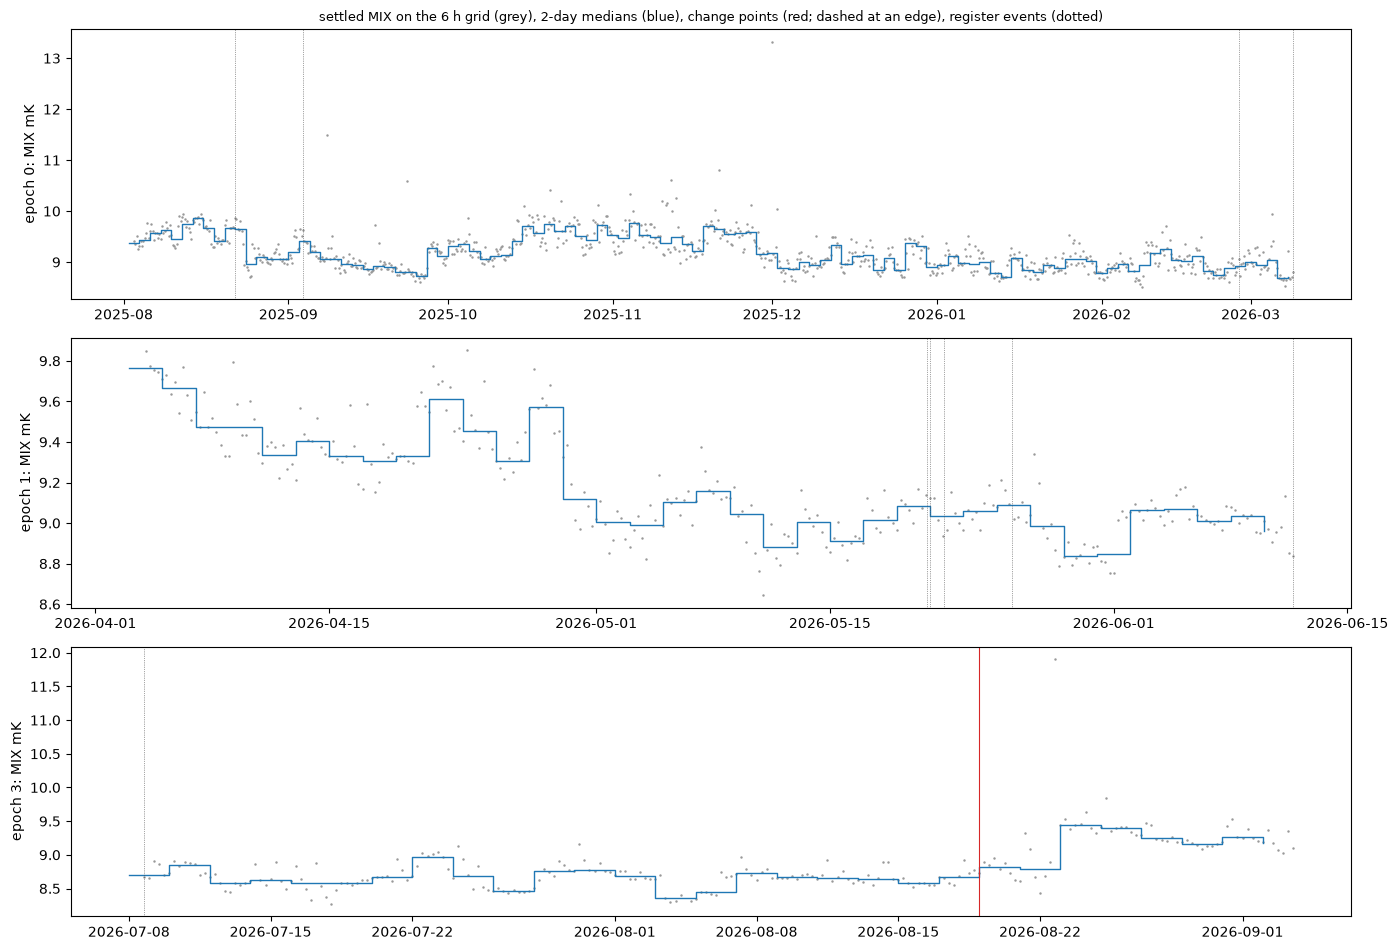

In [9]:
bb["min_seg"] = MIN_SEG
bb["scan"] = ~bb["epoch"].map(fits["plateau"]).astype(bool)  # no plateau: CUSUM reads wander as steps, use the jump scan


def find_cps(df: pd.DataFrame) -> tuple[pd.DataFrame, pd.DataFrame]:
    """Change points per epoch with the events within 2 days, and the eligible bins."""
    cp, elig = methods.change_points(df, ["epoch"], col="y", scan_col="scan")
    cp["near"] = methods.near(cp["t"], EV["at"], NEAR_EVENT)
    cp["event"] = ["; ".join(EV.loc[(EV["at"] - t).abs() <= NEAR_EVENT, "label"]) for t in cp["t"]]
    cp["shift_over_fast_sd"] = cp["shift"] / cp["epoch"].map(fast)
    elig["near"] = methods.near(elig["t"], EV["at"], NEAR_EVENT)
    return cp, elig


def show_cps(cp: pd.DataFrame, elig: pd.DataFrame) -> None:
    """Display the change points and their matched share against chance."""
    with pd.option_context("display.float_format", "{:.4g}".format):
        display(cp.assign(t=cp["t"].dt.strftime("%Y-%m-%d"))[["epoch", "t", "method", "stat", "crit", "shift",
                                                              "shift_over_fast_sd", "edge", "event"]])
    print("change points, matched share and chance per epoch:")
    display(elig.groupby("epoch")["near"].mean().rename("chance").to_frame()
            .join(cp.groupby("epoch")["near"].agg(["size", "mean"]), how="left").fillna({"size": 0}).round(3))


cp, elig = find_cps(bb)
print("2-day bins per epoch:", bb.groupby("epoch").size().to_dict(), "| bandwidth (bins):", bb.groupby("epoch")["block"].first().to_dict(),
      "| jump scan:", bb.groupby("epoch")["scan"].first().to_dict())
print(f"change points (CUSUM where the ratio levels off, else the jump scan with a {MIN_SEG}-bin window): first bin after",
      "the split, method, statistic and critical value, shift in mK and in B1 fast sd, edge, events within 2 days:")
show_cps(cp, elig)

fig, axes = plt.subplots(len(use), 1, figsize=(14, 3.2 * len(use)))
for axx, k in zip(np.atleast_1d(axes), use):
    s = g[g["epoch"] == k]
    axx.plot(s["t"], s["y"], ".", ms=1.5, color="0.6")
    b = bb[bb["epoch"] == k]
    axx.step(b["t"], b["y"], where="post", color="C0", lw=1)
    for tt, edge in cp.loc[cp["epoch"] == k, ["t", "edge"]].itertuples(index=False):
        axx.axvline(tt, color="C3", lw=0.8, ls="--" if edge else "-")
    e = EV[EV["at"].between(s["t"].min(), s["t"].max())]
    for tt in e["at"]:
        axx.axvline(tt, color="0.3", lw=0.5, ls=":")
    axx.set_ylabel(f"epoch {k}: MIX mK")
np.atleast_1d(axes)[0].set_title("settled MIX on the 6 h grid (grey), 2-day medians (blue), change points (red; dashed at an edge), "
                                 "register events (dotted)", fontsize=9)
fig.tight_layout()
out = FIG / "c3_mix.png"
fig.savefig(out, dpi=120)
print("saved", out.relative_to(REPO_ROOT))

**Results.**

- Epochs 0 and 1 (jump scan) have no change point. Epoch 3 (CUSUM, bandwidth 7 bins) has one, on 2026-08-19: +0.511 mK or 6.76 fast sd, with statistic 4.77 against 2.28, not at an edge.
- No register event is within 2 days of it. But epoch 3's chance share is 0 - none of its bins sits within 2 days of an event - so the match test can't say anything there.
- The figure is [c3_mix.png](../../docs/figures/eda/c3_mix.png).

Epoch 3's plateau was a close call, so we rerun it the other way: the jump scan for its change points, and a 28-day block for its drift.

In [10]:
alt, alt_elig = find_cps(bb.assign(scan=True))
print("change points with the jump scan on every epoch (epochs 0 and 1 as above):")
show_cps(alt, alt_elig)

s = bb[bb["epoch"] == 3]
days = ((s["t"] - s["t"].iloc[0]) / pd.Timedelta("1D")).to_numpy()
bw = int(np.ceil(max(LAGS) * SLOT / pd.Timedelta(BIN)))  # 28 days in 2-day bins
b, se = methods.ols_slope_hac(days, s["y"].to_numpy(), bw)
crit = methods.hac_crit(len(s), bw)
print(f"epoch 3 drift with a 28-day block (bandwidth {bw} bins): OLS {30 * b:.4g} mK per 30 days, "
      f"interval {30 * (b - crit * se):.4g} to {30 * (b + crit * se):.4g} (critical value {crit:.4g}), "
      f"blocks {days[-1] / 28:.3g}")

change points with the jump scan on every epoch (epochs 0 and 1 as above):


,epoch,t,method,stat,crit,shift,shift_over_fast_sd,edge,event
0,3,2026-08-21,scan,8.223,4.222,0.6647,8.782,False,


change points, matched share and chance per epoch:


,chance,size,mean
epoch,,,
0,0.068,0.0,NaN
1,0.179,0.0,NaN
3,0.000,1.0,0.0


epoch 3 drift with a 28-day block (bandwidth 14 bins): OLS 0.3096 mK per 30 days, interval -0.1536 to 0.7728 (critical value 4.401), blocks 2


**Results.**

- With the jump scan, epoch 3's change point moves two days to 2026-08-21 (+0.665 mK, statistic 8.22 against 4.22). Epochs 0 and 1 are unchanged.
- With a 28-day block, epoch 3's drift interval is −0.154 to +0.773 mK per 30 days over 2 blocks, so it still includes 0.
- Neither epoch 3 result depends on the plateau call.

## Conclusion

| Result | Status |
|---|---|
| Epochs 0, 1 and 3 reach a signal ratio of 2 at 2 days (2.31, 2.82, 3.61); epoch 2 has no B1 noise row | Analysed at 2 days or more |
| The ratio climbs out to 28 days; exponential for epochs 0 and 3 ($\tau$ 10.8 and 9.37 days), random walk for 1 | Blocks of 28 days for epochs 0 and 1, 14 for epoch 3 |
| No epoch has 30+ blocks (7.79, 2.43, 4) | Slopes describe each epoch, not trends |
| Epochs 0 and 1 drift down (intervals exclude 0); epoch 3's rise includes 0, with either block | Descriptive only |
| One change point, epoch 3 on 2026-08-19 (+0.511 mK), 08-21 with the jump scan; no register event, but chance is 0 there | A comparison date for Phase 02 |